# Sea surface height in ACCESS-OM3 and observations

## Setting up

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5

https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/512462625

 - SSH - SEALEVEL_GLO_PHY_L4_MY_008_047 is in kj13 /g/data/kj13/datasets/cosima/CMEMS and have started a CMORiser in ESMValTool working for monthly
 - AVISO Altimetry Antarctic -kj13 : /g/data/kj13/datasets/cosima/AVISO-Altimetry

Both the above are also in:
 - /g/data/av17/access-nri-temporary/OM3/CMEMS
 - /g/data/av17/access-nri-temporary/OM3/AVISO-Altimetry

Hacked from:
 - https://cosima-recipes.readthedocs.io/en/latest/02-Appetisers/Compare_SSH_model_obs.html (nb: `ua8` is no longer accepting new members)
 - https://github.com/ACCESS-Community-Hub/access-om3-paper-1/blob/main/notebooks/SST.ipynb

Related chat:
 - https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/544659613
 - https://github.com/COSIMA/cosima-recipes/issues/549

NB: with 25km monthly output runs okay on an ARE "large" job.

**If using the daily sattelite obs one needs to use `normalsr` queue with 104 cores/496 Gb**

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# Averaging window: last NYEARS complete years, or an explicit [first, last] period
averaging_period = None   # e.g. [1905, 1909]; None = automatic
NYEARS = 10

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-20-01-2026-om3-update/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-20-01-2026-om3-update/"
nbname = "SSH.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

In [4]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default
import glob

In [5]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42557,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45147,Total threads: 1
Dashboard: http://127.0.0.1:37635/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:42675,


In [6]:
from model_agnostic import years_window, year_slice, complete_years


## SSH from 0.25$^{\circ}$ ACCESS-OM3 model output

In [7]:
from exptdata_access import get_exptname_from_path
exptname = get_exptname_from_path(esm_file)
from exptdata_access import guess_experiment_from_esm_file
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

In [8]:
exptname

'cm3-run-20-01-2026-om3-update'

In [9]:
from model_agnostic import get_lon_lat_from_catalog
geolon, geolat = get_lon_lat_from_catalog(datastore)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


In [10]:
variable = "zos"
model_all = datastore.search(variable=variable).to_dask(
    xarray_open_kwargs = dict(
        chunks={"time": -1},
        decode_timedelta=True
    ),
    xarray_combine_by_coords_kwargs=dict(
        compat="override",
        data_vars="minimal",
        coords="minimal"
    )
)[variable].cf.assign_coords({ "longitude": geolon, "latitude": geolat })

In [11]:
#model_all

In [12]:
# omit latitudes with grid bug https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
# -- only affects the 25km-iaf-test-for-AK-expt-7df5ef4c experiment specifically
if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
    model_all = model_all.isel(yh=slice(10, None))
    geolon = geolon.isel(yh=slice(10, None))
    geolat = geolat.isel(yh=slice(10, None))

In [13]:
# 1. Model: explicit period if given, else last NYEARS complete years
om3_window = years_window(model_all.time, NYEARS, period=averaging_period)
print("Model averaging window:", om3_window)

# Total length of the model record, captured here because model_all is narrowed to
# om3_window further down. The cj877 reference window (CM3 only) needs the run's
# full length, not the averaging window.
om3_nyears_total = len(complete_years(model_all.time))
print("Model record length (complete years):", om3_nyears_total)


Model averaging window: (2071, 2080)
Model record length (complete years): 100


In [14]:
model_all.time.values[0] # initial date in data

np.datetime64('1981-01-16T12:00:00.000000000')

In [15]:
model_all.time.values[-1] # final date in data

np.datetime64('2080-12-16T12:00:00.000000000')

In [16]:
timerange = year_slice(om3_window)


In [17]:
om3_window


(2071, 2080)

In [18]:
timerange


slice('2071', '2080', None)

In [19]:
model_all = model_all.sel(time=timerange)

In [20]:
%%time
model_mean = model_all.mean('time').load()

CPU times: user 483 ms, sys: 238 ms, total: 721 ms
Wall time: 1.17 s


In [21]:
%%time
# this should really use the square field (although it makes the om2 comparison apples-to-oranges)
model_std = model_all.std('time').load()

CPU times: user 729 ms, sys: 238 ms, total: 966 ms
Wall time: 1.48 s


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


## SSH from 0.25$^{\circ}$ ACCESS-OM2 model output

In [22]:
# SSH variable in ACCESS-OM2 models (ACCESS-CM2 cj877 when running CM3)
variable = 'sea_level'

# reference-window length comes from the OM3/CM3 window and is also used
# for the observation window below, so it applies to both branches
ref_nyears = om3_window[1] - om3_window[0] + 1

if model_name == "ACCESS-CM3":
    # ACCESS-CM2 cj877 control archive, as used by the other CM3-capable
    # notebooks. cj877's model calendar isn't tied to real dates, so match the
    # CM3 run's *spin-up stage* rather than its calendar: the last `ref_nyears`
    # complete years of cj877's first `cj877_max_year` years, where that cap is
    # the length of the CM3 record. cj877 is still drifting at this age (its
    # global-mean ocean temperature rises ~0.7 K between model years 50 and 502),
    # so its equilibrated tail is not a like-for-like reference for a 50-year run.
    # Same convention as Equatorial_pacific.ipynb and Bottom_age_tracer_in_ACCESS_OM3.ipynb.
    from pathlib import Path
    cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")
    data_name = "ACCESS-CM2"
    cj877_max_year = om3_nyears_total  # NOT model_all, which is narrowed to om3_window above
    files = sorted(cm2_dir.glob(f"ocean-2d-{variable}-1-monthly-mean-ym_*.nc"))
    if not files:
        raise FileNotFoundError(f"No cj877 monthly files found for {variable!r}")
    files = [f for f in files if int(f.stem.split("_")[-2]) <= cj877_max_year]
    if not files:
        raise FileNotFoundError(f"No cj877 {variable!r} files found for years 1-{cj877_max_year}")
    ds = xr.open_mfdataset(
        files, combine="by_coords", parallel=True,
        chunks={"time": 1, "yt_ocean": -1, "xt_ocean": -1},
        decode_timedelta=True,
        use_cftime=True,  # cj877 model years can't be datetime64
        data_vars="minimal", coords="minimal", compat="override",
    )
    # so the shared title/annotation code below works for CM3 too
    ref_window = years_window(ds[variable].time, ref_nyears, frequency="monthly")
    print("cj877 reference window (model years):", ref_window)
    ssh025 = ds[variable].sel(time=year_slice(ref_window))
else:
    data_name = "ACCESS-OM2"

    catalog = intake.cat.access_nri
    var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable=variable, frequency='1mon')
    ds = var_search.to_dask()
    # 2. Reference run: match the selected model window where available.
    #    Partial overlap warns; no overlap falls back to the same number of
    #    complete years at the start of the reference run, with a warning.
    ref_window = years_window(ds.time, ref_nyears, within=om3_window, fallback="last")
    print('OM2 reference window:', ref_window)
    ssh025 = ds[variable].sel(time=year_slice(ref_window))


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1521580b1010>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x150d7a7af110>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15143f71e210>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15143d62c6b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14bbf268cad0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x154c36823f80>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


... (147 outputs left out)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14cefca28a10>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:767: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  return self.func(*new_argspec, **kwargs)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:767: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  return self.func(*new_argspec, **kwargs)


cj877 reference window (model years): (91, 100)


You can see we have a very large number of chunks, so lets rechunk.

In [23]:
ssh025 = ssh025.chunk({'time': 'auto'})

In [24]:
%%time
#this cell will take a bit (few minutes)
# 0.25 deg:
ssh025_mean = ssh025.mean(dim='time').load()
ssh025_std  = ssh025.std(dim='time', skipna=False).load()

CPU times: user 1.75 s, sys: 594 ms, total: 2.35 s
Wall time: 3.44 s


In [25]:
if model_name == "ACCESS-CM3":
    geolon_t_025 = xr.open_dataset(cm2_dir / "ocean-2d-geolon_t.nc").geolon_t
    geolat_t_025 = xr.open_dataset(cm2_dir / "ocean-2d-geolat_t.nc").geolat_t
else:
    var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="area_t")
    ds = var_search.search(path=var_search.df["path"][0]).to_dask()
    geolon_t_025 = ds.geolon_t
    geolat_t_025 = ds.geolat_t

ssh025_mean = ssh025_mean.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})
ssh025_std = ssh025_std.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1482971f8e90>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x148296cfb080>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1482971f7dd0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x148296cf4110>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14829721b5f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1482971f0470>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1482959da870>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/jobfs/185315511.gadi-pbs/ipykernel_1951983/485215302.py:2: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates prior reform date (1582-10-15). To silence this warning specify 'use_cftime=True'.
  geolon_t_025 = xr.open_dataset(cm2_dir / "ocean-2d-geolon_t.nc").geolon_t


/jobfs/185315511.gadi-pbs/ipykernel_1951983/485215302.py:3: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates prior reform date (1582-10-15). To silence this warning specify 'use_cftime=True'.
  geolat_t_025 = xr.open_dataset(cm2_dir / "ocean-2d-geolat_t.nc").geolat_t


## Read in observations

In [26]:
import numpy as np
cmems_root = '/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/'
# Only open the last NYEARS+1 year directories (the final one may be partial;
# years_window below picks the complete ones)
cmems_years = sorted(int(os.path.basename(p)) for p in glob.glob(cmems_root + '[0-9]' * 4))
filenames = []
for year in cmems_years[-(NYEARS + 1):]:
    filenames.extend(sorted(glob.glob(cmems_root + str(year) + '/*/*.nc')))
print(len(filenames), 'CMEMS files from', cmems_years[-(NYEARS + 1):])


4017 CMEMS files from [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [27]:
%%time
#this was taking ages on daily data, so Dougie suggested adding: data_vars='minimal', coords='minimal', compat='override' -- should avoid any issues with messy metadata -- see docs: https://docs.xarray.dev/en/stable/generated/xarray.open_mfdataset.html
cmems = xr.open_mfdataset(filenames, parallel=True,concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override',chunks="auto")

#even betterer (I think these extra ones actually slowed it down a bit?)
#concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override'

#faster with 28 cores compared to 14 (~1.5 minutes)

CPU times: user 1min 42s, sys: 53.6 s, total: 2min 36s
Wall time: 2min 28s


In [28]:
#filenames

In [29]:
# The absolute dynamic topography is the sea surface height above geoid; adt=sla+mdt
obs_ssh = cmems.adt.rename('adt_cmems')
# 3. Observations: their own window (don't match RYF model years to real years)
obs_window = years_window(obs_ssh.time, ref_nyears)
print('CMEMS window:', obs_window)
obs_ssh = obs_ssh.sel(time=year_slice(obs_window))


CMEMS window: (2014, 2023)


In [30]:
%%time
#on daily data this cell didn't run properly with 28 cores/252 gb. Needed `normalsr` queue with 104 cores/496 Gb
obs_ssh_mean = obs_ssh.mean(dim='time').load()
obs_ssh_std  = obs_ssh.std(dim='time', skipna=False).load()

CPU times: user 1min 41s, sys: 35 s, total: 2min 16s
Wall time: 5min 32s


In [31]:
#from Anton -- could use this kind of command to reduce the obs down to the model frequency but I think it makes more sense to use ssh^2 fields from model.
#obs_ssh_mean= obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)
#obs_ssh_std = obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)

#AS: sorry - this should be a resample not a groupby !
#AS: groupby would give a climatology (a monthly mean of all years). resample would give a mean for every month (e.g like change from daily to monthly data)

## Plot ACCESS-OM2, ACCESS-OM3 and obs


Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-20-01-2026-om3-update/mkmd/SSH_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-20-01-2026-om3-update/mkmd/SSH.md
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-20-01-2026-om3-update/mkmd/SSH.md successfully.
CPU times: user 1min 50s, sys: 27.6 s, total: 2min 18s
Wall time: 1min 50s


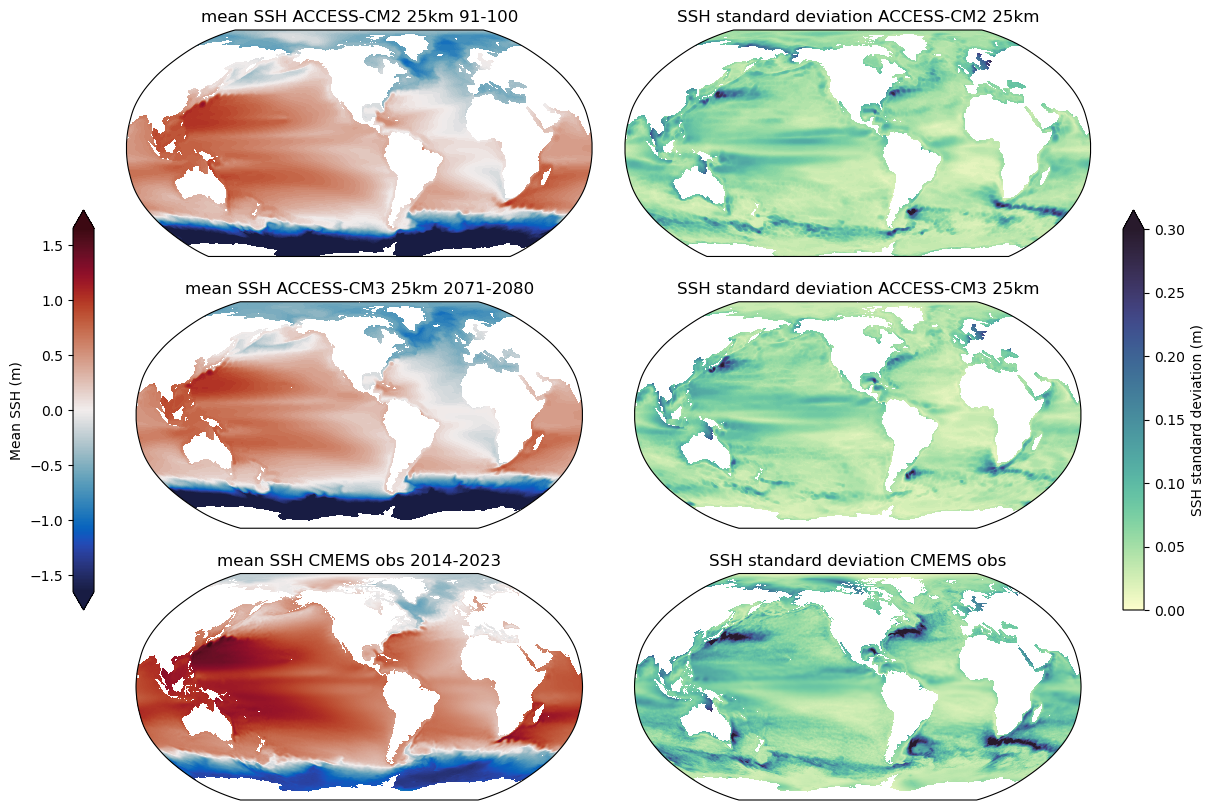

In [32]:
%%time

# nominal resolution from the model grid, so titles are right for any OM3 resolution
nx = model_mean.sizes["xh"]
om3_res = {360: "100km", 1440: "25km", 4320: "8km"}.get(nx)

projection = ccrs.Robinson(central_longitude=-100)

fig, axes = plt.subplots(nrows = 3, ncols = 2, figsize = (14, 10),
                         subplot_kw={'projection': projection})
plt.subplots_adjust(wspace=-0.15)

max_std = 0.3
max_mean = 1.65

# mean SSH plots
ax = axes[0, 0]
p1 = ssh025_mean.plot.contourf(
    ax = ax,
    x = "geolon_t",
    y = "geolat_t",
    levels = 100,
    vmin = -max_mean,
    vmax = +max_mean,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
ax.set_title(f'mean SSH {data_name} 25km {ref_window[0]}-{ref_window[1]}')

ax = axes[1, 0]
p1 = model_mean.plot.contourf(
    ax = ax,
    x = "xh",
    y = "yh",
    levels = 100,
    vmin = -max_mean,
    vmax = +max_mean,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
ax.set_title(f'mean SSH {model_name} {om3_res} {om3_window[0]}-{om3_window[1]}')

ax = axes[2, 0]
p1 = obs_ssh_mean.plot(ax=ax, transform=ccrs.PlateCarree(),
                       cmap=cm.cm.balance, vmin=-max_mean, vmax=max_mean, add_colorbar=False)
ax.set_title(f'mean SSH CMEMS obs {obs_window[0]}-{obs_window[1]}')

# std SSH plots
ax = axes[0, 1]
p2 = ssh025_std.plot.contourf(
    ax = ax,
    x = "geolon_t",
    y = "geolat_t",
    levels = 100,
    vmin = 0,
    vmax = max_std,
    add_colorbar=False,
    cmap = cm.cm.deep,
    transform = ccrs.PlateCarree())
ax.set_title(f'SSH standard deviation {data_name} 25km')

ax = axes[1, 1]
p2 = model_std.plot.contourf(
    ax = ax,
    x = "xh",
    y = "yh",
    levels = 100,
    vmin = 0,
    vmax = max_std,
    add_colorbar=False,
    cmap = cm.cm.deep,
    transform = ccrs.PlateCarree())
ax.set_title(f'SSH standard deviation {model_name} {om3_res}')

ax = axes[2, 1]
p2 = obs_ssh_std.plot(ax=ax, transform=ccrs.PlateCarree(),cmap=cm.cm.deep, vmin=0, vmax=max_std, add_colorbar=False)
ax.set_title('SSH standard deviation CMEMS obs')

# Colorbars
ax_cb1 = plt.axes([0.13, 0.3, 0.015, 0.4])
cb = plt.colorbar(p1, cax=ax_cb1, extend='both', label='Mean SSH (m)')
ax_cb1.yaxis.set_ticks_position('left')
ax_cb1.yaxis.set_label_position('left')

ax_cb2 = plt.axes([0.88, 0.3, 0.015, 0.4])
cb = plt.colorbar(p2, cax=ax_cb2, extend='max', label='SSH standard deviation (m)');
mkmd.savefig(fig, "Sea Surface Height", f"Sea surface height mean and standard deviation comparison for {model_name} and {data_name}. [GitHub issue: Global dynamic sea level](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/4) [GitHub issue: Sea level anomaly std dev](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5)")

In [33]:
plt.show()